# Solution: Level 3 — Advanced: Visualisation and End-to-End Analysis

**Course:** Python & Data Analytics &nbsp;|&nbsp; **Program:** B.Tech Technical Training – CSE A & B

**What this set covers**
- **Part A – Visualisation toolkit:** line, bar, histogram, box, scatter, heatmap and multi-panel figures with Matplotlib and Seaborn
- **Part B – End-to-end case study:** a complete question → clean → analyse → visualise → conclude workflow
- **Part C – Insight reporting:** turning numbers into clear statements a manager can act on

The setup cell gives you `load_sales()` and `load_students()`. They return **cleaned** data using the same steps you
wrote in Level 2, so you can focus on analysis and charts here.

**Rules for every chart in this set:** it must have a title, labelled axes (with units) and a legend
whenever there is more than one series. A chart without these will not get full marks in the projects.

> **Instructor solution.** Attempt the exercises yourself before reading this. Your answers may differ in method and still be correct.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = "../../datasets/"
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 4.5)
pd.set_option("display.float_format", "{:,.2f}".format)

SUBJECTS = ["Mathematics", "Physics", "Programming", "English", "Electronics"]


def load_sales():
    """Load sales_data.csv and apply the Level 2 cleaning steps."""
    df = pd.read_csv(DATA_DIR + "sales_data.csv").drop_duplicates().reset_index(drop=True)
    df["Region"] = df["Region"].str.strip().str.title()
    df["Unit_Price"] = pd.to_numeric(
        df["Unit_Price"].astype(str).str.replace("Rs.", "", regex=False), errors="coerce")
    for col in ["Unit_Price", "Quantity"]:
        df[col] = df[col].fillna(df.groupby("Product")[col].transform("median"))
    df["Quantity"] = df["Quantity"].round().astype(int)
    df["Customer_Segment"] = df["Customer_Segment"].fillna("Unknown")
    df["Order_Date"] = pd.to_datetime(df["Order_Date"])
    df["Month"] = df["Order_Date"].dt.month
    df["Revenue"] = (df["Quantity"] * df["Unit_Price"] * (1 - df["Discount"])).round(2)
    return df


def load_students():
    """Load student_performance.csv and apply the Level 2 cleaning steps."""
    df = pd.read_csv(DATA_DIR + "student_performance.csv").drop_duplicates().reset_index(drop=True)
    df["Gender"] = df["Gender"].str.strip().str.lower().map(
        {"m": "Male", "male": "Male", "f": "Female", "female": "Female"})
    for col in ["Attendance_Pct"] + SUBJECTS:
        df[col] = df[col].where(df[col].between(0, 100))
    return df


sales = load_sales()
students = load_students()
print("sales:", sales.shape, "| students:", students.shape)

sales: (1200, 13) | students: (240, 13)


## Part A — Visualisation toolkit

### Exercise 3.1 — Line chart: a trend over time

Plot **weekly** total revenue across 2024 as a line chart. Add a dashed horizontal line at the average weekly revenue. Show the y-axis in lakhs.

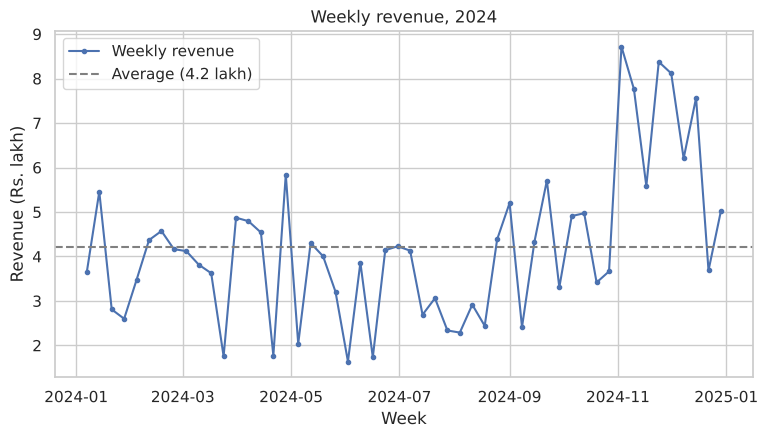

In [2]:
weekly = sales.set_index("Order_Date").resample("W")["Revenue"].sum() / 1e5
weekly = weekly.iloc[:-1]   # the last "week" holds only 30-31 Dec, so it is incomplete

fig, ax = plt.subplots()
ax.plot(weekly.index, weekly.values, marker="o", markersize=3, linewidth=1.5, label="Weekly revenue")
ax.axhline(weekly.mean(), color="grey", linestyle="--", label=f"Average ({weekly.mean():.1f} lakh)")
ax.set_title("Weekly revenue, 2024")
ax.set_xlabel("Week")
ax.set_ylabel("Revenue (Rs. lakh)")
ax.legend()
plt.show()

> **Note:** Weeks end on Sunday, so the final bin covers only 30–31 December. A partial period always looks like a sudden drop, so it is removed. The rise in October–November is the festive season. It is easier to see in a weekly series than in a daily one, which is very noisy.

### Exercise 3.2 — Bar chart: comparing categories

Make a **horizontal** bar chart of total revenue by `Payment_Mode`, sorted so the largest bar is at the top. Write the value (in lakhs) at the end of each bar.

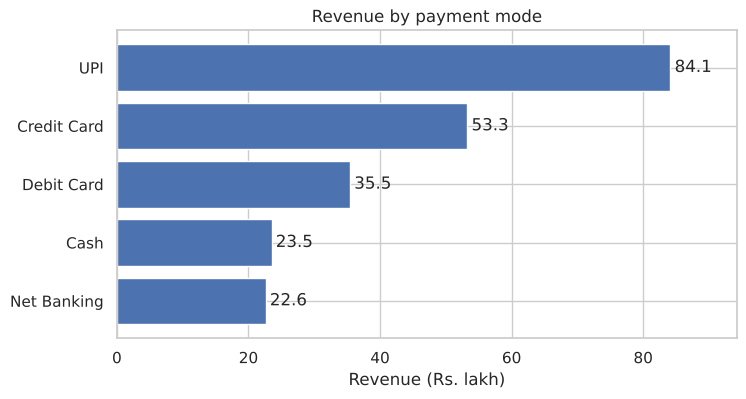

In [3]:
pay = (sales.groupby("Payment_Mode")["Revenue"].sum() / 1e5).sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(pay.index, pay.values, color=sns.color_palette()[0])
ax.bar_label(ax.containers[0], fmt="%.1f", padding=3)
ax.set_title("Revenue by payment mode")
ax.set_xlabel("Revenue (Rs. lakh)")
ax.set_ylabel("")
ax.set_xlim(0, pay.max() * 1.12)
plt.show()

### Exercise 3.3 — Histogram: the shape of a distribution

Plot the distribution of order `Revenue`. It is heavily skewed, so plot it a second time on a **log scale**. In a markdown cell, describe what each version shows.

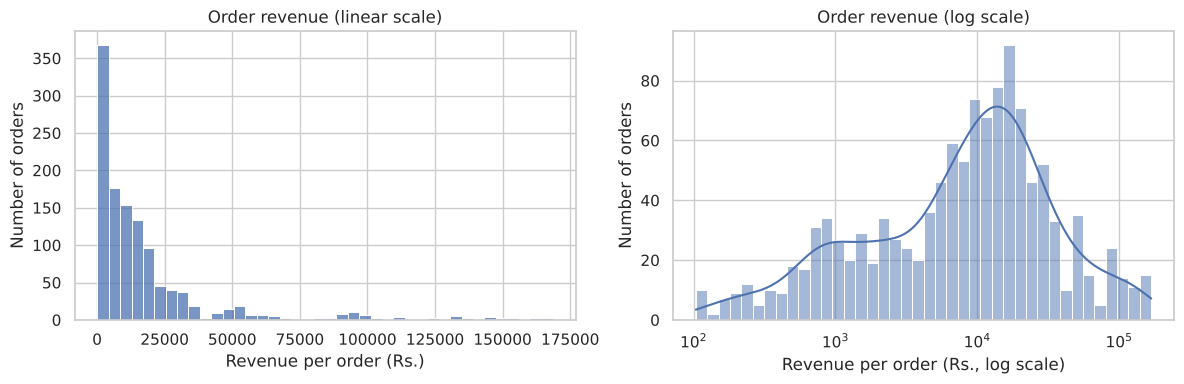

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=sales, x="Revenue", bins=40, ax=axes[0])
axes[0].set_title("Order revenue (linear scale)")
axes[0].set_xlabel("Revenue per order (Rs.)")

sns.histplot(data=sales, x="Revenue", bins=40, log_scale=True, kde=True, ax=axes[1])
axes[1].set_title("Order revenue (log scale)")
axes[1].set_xlabel("Revenue per order (Rs., log scale)")
for ax in axes:
    ax.set_ylabel("Number of orders")
plt.tight_layout()
plt.show()

> **Note:** On the linear scale almost all orders are squeezed into the first bar, because a few laptop and sofa orders are huge. The log scale shows that there are really several groups of orders: cheap stationery, mid-priced items and expensive electronics or furniture.

### Exercise 3.4 — Box plot: comparing distributions

Compare the Programming marks of **hostellers vs day scholars**, split by `Section`, using a box plot. Which group has the highest median? Which has the widest spread?

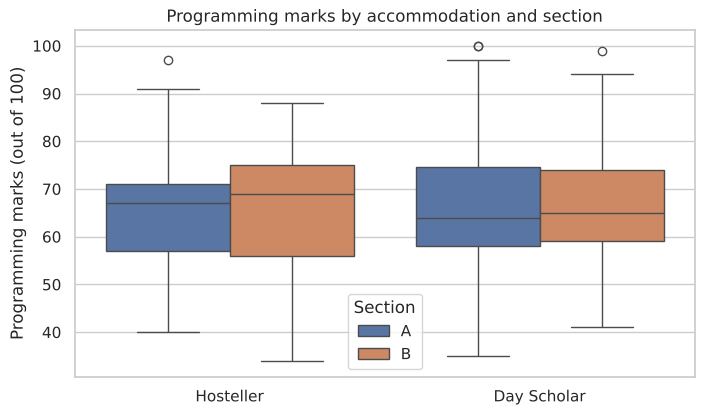

50%   min    max   std
Accommodation Section                         
Day Scholar   A       64.00 35.00 100.00 13.20
              B       65.00 41.00  99.00 11.80
Hosteller     A       67.00 40.00  97.00 11.90
              B       69.00 34.00  88.00 12.40

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=students, x="Accommodation", y="Programming", hue="Section", ax=ax)
ax.set_title("Programming marks by accommodation and section")
ax.set_xlabel("")
ax.set_ylabel("Programming marks (out of 100)")
plt.show()

students.groupby(["Accommodation", "Section"])["Programming"].describe()[["50%", "min", "max", "std"]].round(1)

### Exercise 3.5 — Scatter plot: relationships

Plot `Attendance_Pct` against `Programming` marks, coloured by `Section`, with a regression line. Calculate the correlation coefficient and say in words how strong the relationship is.

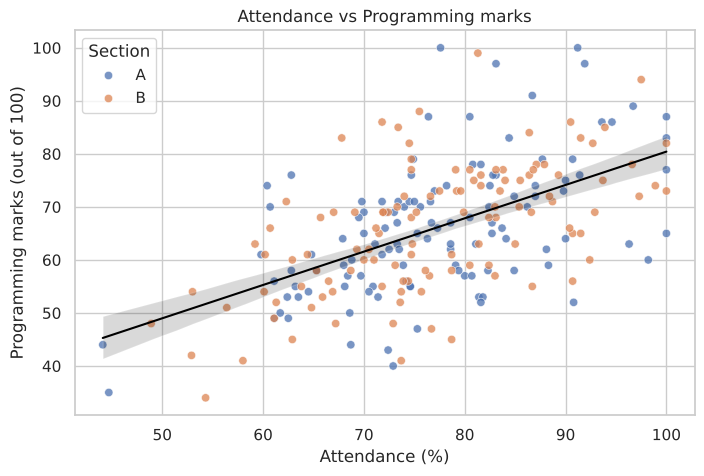

Correlation r = 0.56


In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=students, x="Attendance_Pct", y="Programming", hue="Section", alpha=0.75, ax=ax)
sns.regplot(data=students, x="Attendance_Pct", y="Programming", scatter=False, color="black",
            line_kws={"linewidth": 1.5}, ax=ax)
ax.set_title("Attendance vs Programming marks")
ax.set_xlabel("Attendance (%)")
ax.set_ylabel("Programming marks (out of 100)")
plt.show()

r = students["Attendance_Pct"].corr(students["Programming"])
print(f"Correlation r = {r:.2f}")

> **Note:** An r of about 0.5–0.6 is a **moderate positive** relationship: students who attend more tend to score higher, but attendance alone does not decide the mark. Correlation does not prove that attending *causes* better marks.

### Exercise 3.6 — Heatmap: many relationships at once

Draw a correlation heatmap of attendance, study hours, previous GPA and the five subjects. Show the numbers in the cells and use a diverging colour map centred on 0. Which factor is most strongly linked to marks?

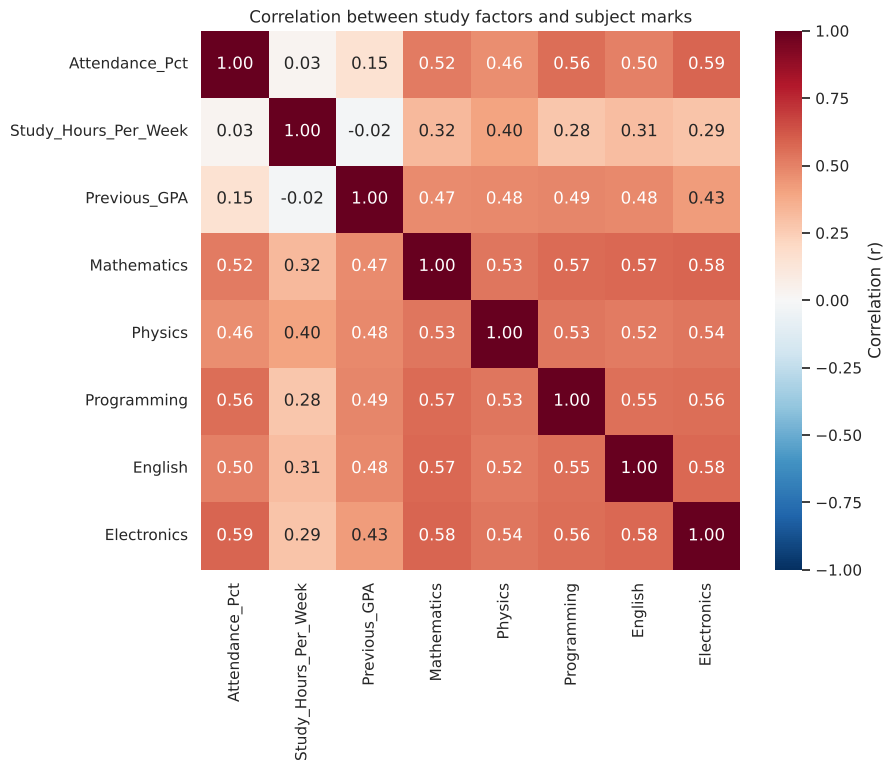

Attendance_Pct         0.53
Study_Hours_Per_Week   0.32
Previous_GPA           0.47
dtype: float64


In [7]:
cols = ["Attendance_Pct", "Study_Hours_Per_Week", "Previous_GPA"] + SUBJECTS
corr = students[cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            cbar_kws={"label": "Correlation (r)"}, ax=ax)
ax.set_title("Correlation between study factors and subject marks")
plt.show()

print(corr.loc[["Attendance_Pct", "Study_Hours_Per_Week", "Previous_GPA"], SUBJECTS].mean(axis=1).round(2))

### Exercise 3.7 — Multi-panel figure: a mini dashboard

Load `weather_data.csv`. For **Hyderabad in 2024**, build a 2×2 figure showing:
1. daily max and min temperature (line)
2. monthly total rainfall (bar)
3. distribution of humidity (histogram)
4. max temperature vs humidity (scatter)

Give the whole figure a main title with `fig.suptitle`. Remember to remove the `-99` error codes and the duplicates first.

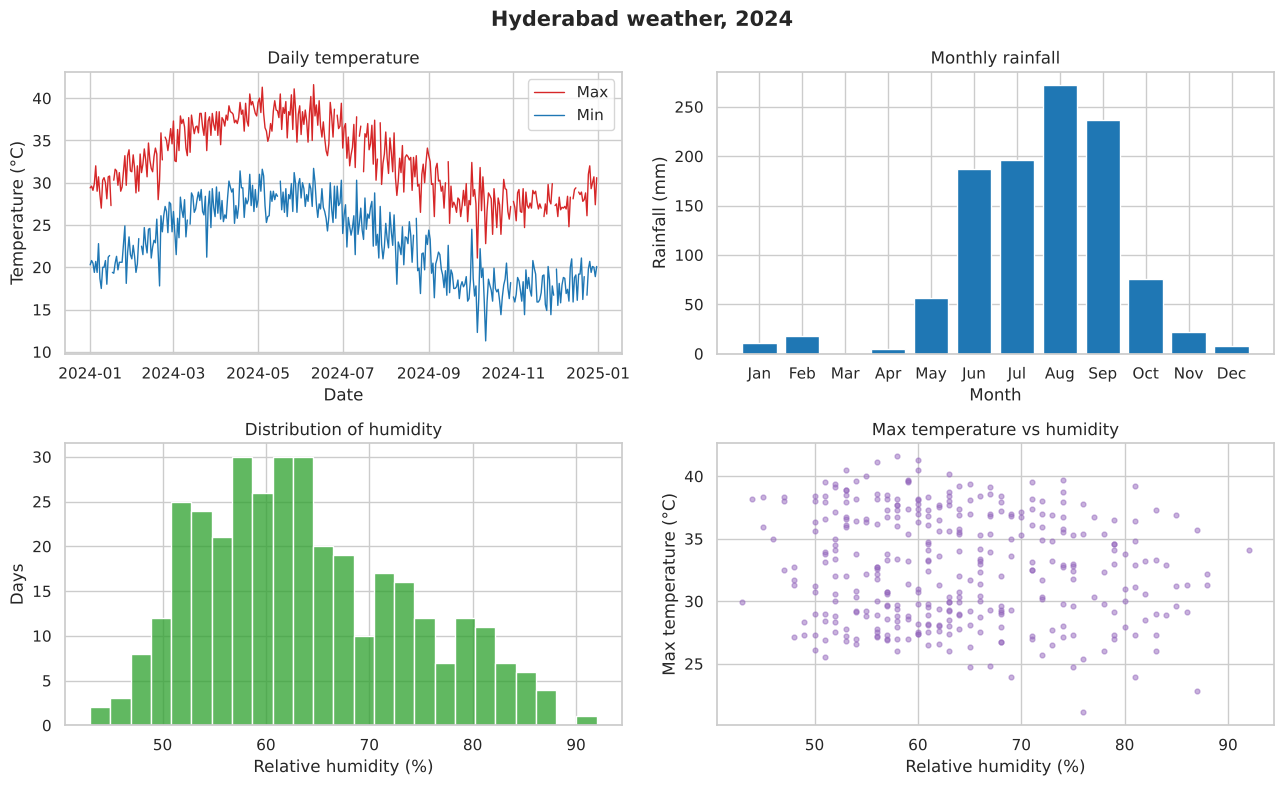

In [8]:
weather = pd.read_csv(DATA_DIR + "weather_data.csv", parse_dates=["Date"]).drop_duplicates()
weather = weather.replace(-99.0, np.nan)
hyd = weather[(weather["City"] == "Hyderabad") & (weather["Date"].dt.year == 2024)].set_index("Date")

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

axes[0, 0].plot(hyd.index, hyd["Max_Temp_C"], label="Max", color="tab:red", linewidth=1)
axes[0, 0].plot(hyd.index, hyd["Min_Temp_C"], label="Min", color="tab:blue", linewidth=1)
axes[0, 0].set(title="Daily temperature", xlabel="Date", ylabel="Temperature (°C)")
axes[0, 0].legend()

monthly_rain = hyd["Rainfall_mm"].resample("ME").sum()
axes[0, 1].bar(monthly_rain.index.strftime("%b"), monthly_rain.values, color="tab:blue")
axes[0, 1].set(title="Monthly rainfall", xlabel="Month", ylabel="Rainfall (mm)")

sns.histplot(hyd["Humidity_Pct"].dropna(), bins=25, ax=axes[1, 0], color="tab:green")
axes[1, 0].set(title="Distribution of humidity", xlabel="Relative humidity (%)", ylabel="Days")

axes[1, 1].scatter(hyd["Humidity_Pct"], hyd["Max_Temp_C"], alpha=0.5, s=12, color="tab:purple")
axes[1, 1].set(title="Max temperature vs humidity", xlabel="Relative humidity (%)", ylabel="Max temperature (°C)")

fig.suptitle("Hyderabad weather, 2024", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

> **Note:** `'ME'` means month-end frequency. With pandas older than 2.2, use `'M'` instead.

### Exercise 3.8 — Saving figures

Re-create the bar chart from 3.2 and save it as `revenue_by_payment_mode.png` at 150 dpi. Then save it again as a `.svg` file. When is each format better?

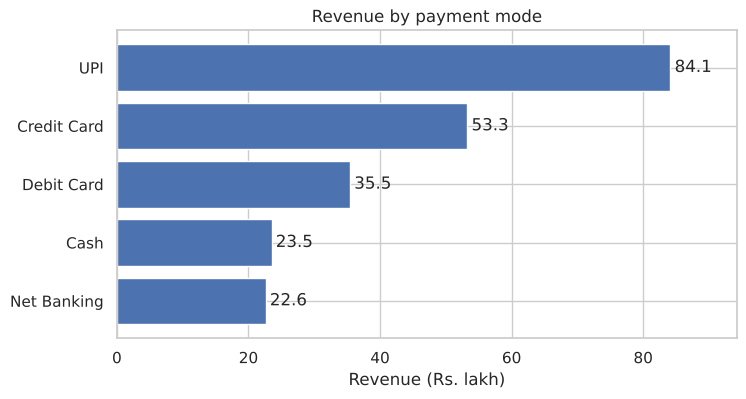

Saved PNG and SVG


In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(pay.index, pay.values)
ax.bar_label(ax.containers[0], fmt="%.1f", padding=3)
ax.set(title="Revenue by payment mode", xlabel="Revenue (Rs. lakh)")
ax.set_xlim(0, pay.max() * 1.12)

fig.savefig("revenue_by_payment_mode.png", dpi=150, bbox_inches="tight")
fig.savefig("revenue_by_payment_mode.svg", bbox_inches="tight")
plt.show()
print("Saved PNG and SVG")

> **Note:** PNG is a fixed grid of pixels. It works everywhere, which makes it good for slides and reports. SVG is a vector format. It stays sharp at any zoom, which makes it better for web pages and print, but some tools cannot open it.

## Part B — End-to-end case study: *Who buys, and how do they pay?*

The marketing team asks: **"Which customer segments bring in the most revenue, how do they prefer to pay, and do
discounts make people buy more?"** Work through the five steps below. Each step has its own exercise.

### Exercise 3.9 — Step 1 — Frame the questions

In a markdown cell, rewrite the marketing team's request as **three precise questions** that data can answer. For each one, name the columns and the calculation you will need.

In [10]:
# The three questions, with the data needed for each:
questions = pd.DataFrame({
    "Question": [
        "Q1. How much revenue and how many orders come from each customer segment, and what is each segment's average order value?",
        "Q2. What share of each segment's revenue is paid through each payment mode?",
        "Q3. Do orders with a higher discount have larger quantities, after allowing for the product category?",
    ],
    "Data and method": [
        "Customer_Segment, Revenue, Order_ID -> groupby + agg (sum, count, mean)",
        "Customer_Segment, Payment_Mode, Revenue -> pivot_table, normalised by row",
        "Discount, Quantity, Category -> groupby Category & Discount, mean Quantity",
    ],
})
with pd.option_context("display.max_colwidth", None):
    display(questions)

,Question,Data and method
0,"Q1. How much revenue and how many orders come from each customer segment, and what is each segment's average order value?","Customer_Segment, Revenue, Order_ID -> groupby + agg (sum, count, mean)"
1,Q2. What share of each segment's revenue is paid through each payment mode?,"Customer_Segment, Payment_Mode, Revenue -> pivot_table, normalised by row"
2,"Q3. Do orders with a higher discount have larger quantities, after allowing for the product category?","Discount, Quantity, Category -> groupby Category & Discount, mean Quantity"


### Exercise 3.10 — Step 2 — Check the data you need

Check the columns needed for your questions: missing values, the distinct values in each category, and how many orders have the segment `'Unknown'`. Decide whether to keep or exclude the `'Unknown'` orders, and justify your decision.

In [11]:
needed = ["Customer_Segment", "Payment_Mode", "Discount", "Quantity", "Category", "Revenue"]
print(sales[needed].isna().sum(), end="\n\n")
for col in ["Customer_Segment", "Payment_Mode", "Discount"]:
    print(sales[col].value_counts().sort_index(), end="\n\n")

unknown_share = (sales["Customer_Segment"] == "Unknown").mean() * 100
print(f"'Unknown' segment: {unknown_share:.1f}% of orders")

Customer_Segment    0
Payment_Mode        0
Discount            0
Quantity            0
Category            0
Revenue             0
dtype: int64

Customer_Segment
Consumer          662
Corporate         366
Small Business    162
Unknown            10
Name: count, dtype: int64

Payment_Mode
Cash           154
Credit Card    271
Debit Card     190
Net Banking    108
UPI            477
Name: count, dtype: int64

Discount
0.00    436
0.05    206
0.10    325
0.15    141
0.20     92
Name: count, dtype: int64

'Unknown' segment: 0.8% of orders


> **Note:** Fewer than 1% of orders are 'Unknown'. Excluding them from the segment comparison will not bias the results. We keep them in all overall totals.

### Exercise 3.11 — Step 3 — Analyse (Q1 and Q2)

Answer Q1 with a summary table per segment: orders, revenue (lakh), share of revenue (%) and average order value. Answer Q2 with a table showing what percentage of each segment's revenue comes from each payment mode (each row should add up to 100%).

In [12]:
known = sales[sales["Customer_Segment"] != "Unknown"]

seg = known.groupby("Customer_Segment").agg(
    Orders=("Order_ID", "count"),
    Revenue_Lakh=("Revenue", lambda s: s.sum() / 1e5),
    Avg_Order_Value=("Revenue", "mean"),
)
seg["Revenue_Share_Pct"] = seg["Revenue_Lakh"] / seg["Revenue_Lakh"].sum() * 100
display(seg.sort_values("Revenue_Lakh", ascending=False).round(1))

pay_mix = pd.crosstab(known["Customer_Segment"], known["Payment_Mode"],
                      values=known["Revenue"], aggfunc="sum", normalize="index") * 100
display(pay_mix.round(1))

,Orders,Revenue_Lakh,Avg_Order_Value,Revenue_Share_Pct
Customer_Segment,,,,
Consumer,662,117.00,"17,667.70",53.90
Corporate,366,75.40,"20,587.60",34.70
Small Business,162,24.90,"15,357.40",11.50


Payment_Mode,Cash,Credit Card,Debit Card,Net Banking,UPI
Customer_Segment,,,,,
Consumer,10.20,22.60,14.70,11.30,41.30
Corporate,10.70,26.20,20.10,10.80,32.20
Small Business,14.10,23.80,11.60,5.30,45.20


### Exercise 3.12 — Step 3 — Analyse (Q3)

Compare the **average quantity per order at each discount level**, separately for each category. Why is it important to split by category here, rather than looking at all orders together?

In [13]:
disc_qty = sales.pivot_table(index="Discount", columns="Category", values="Quantity", aggfunc="mean")
display(disc_qty.round(2))

print("Correlation of discount with quantity, within each category:")
print(sales.groupby("Category")[["Discount", "Quantity"]].corr().xs("Quantity", level=1)["Discount"].round(3))

Category,Clothing,Electronics,Furniture,Office Supplies
Discount,,,,
0.00,5.50,2.79,2.06,5.28
0.05,5.31,3.38,1.79,4.96
0.10,5.44,2.89,2.04,5.32
0.15,4.69,2.40,1.88,4.86
0.20,4.11,2.64,1.78,4.63


Correlation of discount with quantity, within each category:
Category
Clothing          -0.11
Electronics       -0.04
Furniture         -0.08
Office Supplies   -0.05
Name: Discount, dtype: float64


> **Note:** Expensive categories such as Furniture have small quantities (1–3) and cheap ones such as Office Supplies have large ones (1–10). If discount levels were spread unevenly across categories, pooling all orders could suggest a link that is really caused by the mix of categories. Here the correlations within each category are close to zero or slightly negative, so **this data gives no evidence that bigger discounts lead to bigger orders.**

### Exercise 3.13 — Step 4 — Visualise the answers

Create **one figure with two panels** that a marketing manager could understand in 10 seconds:
- left: revenue by segment (bar)
- right: payment-mode mix for each segment (100% stacked bar)

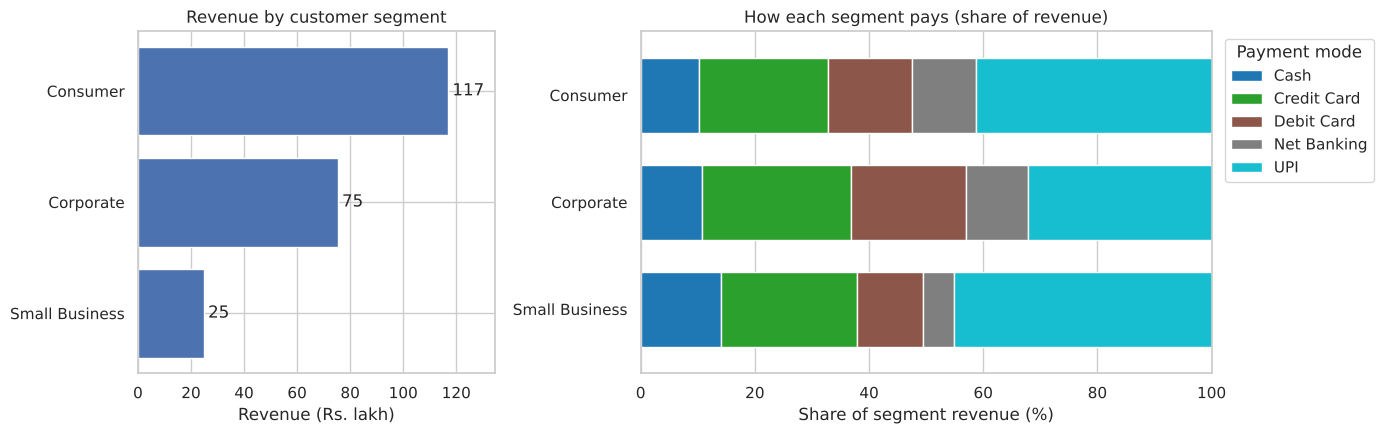

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})

order = seg.sort_values("Revenue_Lakh").index
axes[0].barh(order, seg.loc[order, "Revenue_Lakh"])
axes[0].bar_label(axes[0].containers[0], fmt="%.0f", padding=3)
axes[0].set(title="Revenue by customer segment", xlabel="Revenue (Rs. lakh)")
axes[0].set_xlim(0, seg["Revenue_Lakh"].max() * 1.15)

pay_mix.loc[order].plot(kind="barh", stacked=True, ax=axes[1], width=0.7, colormap="tab10")
axes[1].set(title="How each segment pays (share of revenue)", xlabel="Share of segment revenue (%)", ylabel="")
axes[1].legend(title="Payment mode", bbox_to_anchor=(1.01, 1), loc="upper left")
axes[1].set_xlim(0, 100)

plt.tight_layout()
plt.show()

### Exercise 3.14 — Step 5 — Conclude

Write **three insights** in the format below, each backed by a number from your analysis, followed by **one recommendation**.

> **Insight:** what you found (with a number) → **So what:** why it matters to the business

In [15]:
top_seg = seg["Revenue_Share_Pct"].idxmax()
aov_ratio = seg.loc["Corporate", "Avg_Order_Value"] / seg.loc["Consumer", "Avg_Order_Value"]
upi_share = pay_mix["UPI"].round(1)

print(f"1. {top_seg} customers bring in {seg.loc[top_seg, 'Revenue_Share_Pct']:.0f}% of revenue.")
print(f"2. Corporate average order value is {aov_ratio:.2f}x the Consumer average.")
print(f"3. UPI share of revenue by segment: {upi_share.to_dict()}")
within_r = sales.groupby("Category")[["Discount", "Quantity"]].corr().xs("Quantity", level=1)["Discount"]
print(f"4. Discount-quantity correlation within categories ranges from {within_r.min():.2f} to {within_r.max():.2f}.")

1. Consumer customers bring in 54% of revenue.
2. Corporate average order value is 1.17x the Consumer average.
3. UPI share of revenue by segment: {'Consumer': 41.3, 'Corporate': 32.2, 'Small Business': 45.2}
4. Discount-quantity correlation within categories ranges from -0.11 to -0.04.


> **Note:** **Sample write-up**

1. **Insight:** Consumers generate more than half of all revenue. **So what:** campaigns aimed at individual buyers have the largest reach.
2. **Insight:** UPI is the leading payment mode in every segment, at about a third to almost half of segment revenue. **So what:** UPI-specific offers (cashback) would reach the most buyers.
3. **Insight:** Within each category, orders with bigger discounts are *not* larger; if anything they are slightly smaller. **So what:** discounts may be cutting margin without raising the number of units sold.

**Recommendation:** Run a controlled test in which half the regions get a 10% discount and the other half get a UPI cashback offer of the same cost, and compare units sold. Our data shows a pattern but cannot prove cause and effect.

## Part C — Insight reporting

### Exercise 3.15 — Critique a chart

Run the cell below. It produces a chart that breaks several good-practice rules. List **at least four** problems, then redraw it properly.

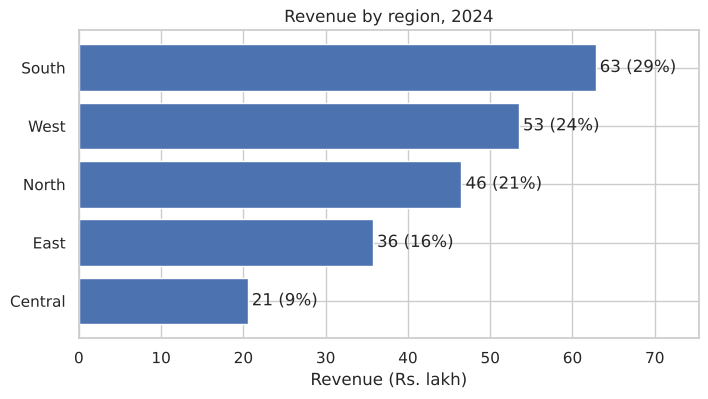

In [16]:
# Problems with the original:
# 1. No title, so the reader does not know what is being shown
# 2. No labels or legend, so the slices cannot be identified
# 3. Repeated, similar colours make slices impossible to tell apart
# 4. A pie chart makes 5 similar-sized parts hard to compare (people judge angles poorly)
# 5. No values or units are shown

better = (sales.groupby("Region")["Revenue"].sum() / 1e5).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(better.index, better.values)
ax.bar_label(ax.containers[0], labels=[f"{v:.0f} ({v / better.sum() * 100:.0f}%)" for v in better.values], padding=3)
ax.set(title="Revenue by region, 2024", xlabel="Revenue (Rs. lakh)")
ax.set_xlim(0, better.max() * 1.2)
plt.show()

---
## Key takeaways
- Choose the chart for the question: **trend** → line, **compare** → bar, **distribution** → histogram or box, **relationship** → scatter or heatmap.
- Skewed data is often clearer on a log scale.
- An analysis is not finished until it answers the original question in plain words, backed by numbers, and says what it cannot prove.